## Clasificacion

Vamos a desarrollar un modelo de Machine Learning que clasifique tumores mamarios como benignos o malignos, utilizando el dataset Breast Cancer Wisconsin Diagnostic, incluido en scikit-learn.
Es un buen ejemplo educativo porque permite recorrer el flujo completo de un proyecto de clasificación: carga de datos, análisis exploratorio, preparación, entrenamiento, predicción y evaluación.









Tumor benigno
Las células analizadas presentan características compatibles con una lesión benigna.











Tumor maligno
Las características celulares analizadas presentan patrones asociados con malignidad.



Las imágenes son ilustrativas. El modelo utilizará mediciones numéricas del dataset, no las imágenes histológicas.
Importante: este ejemplo tiene fines educativos y no debe utilizarse para diagnosticar pacientes ni tomar decisiones clínicas.
1. Conocer el dataset
El dataset contiene 569 muestras y 30 variables numéricas extraídas de imágenes digitalizadas de aspiraciones con aguja fina de masas mamarias.
Característica	Descripción
mean radius	Radio medio de los núcleos celulares
mean texture	Variación de la intensidad de gris
mean perimeter	Perímetro medio
mean area	Área media
mean smoothness	Variación local de los radios
mean concavity	Medida de la concavidad del contorno
Además de las medias, incluye medidas de error y valores extremos de las características.
La variable objetivo tiene dos clases:
- 0: maligno.
- 1: benigno.
scikit-learn utiliza esta codificación en el dataset. En el código la vamos a conservar para las métricas y mostrar las etiquetas legibles al predecir.

Dimensiones: (569, 30)

Primeros registros:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  wo

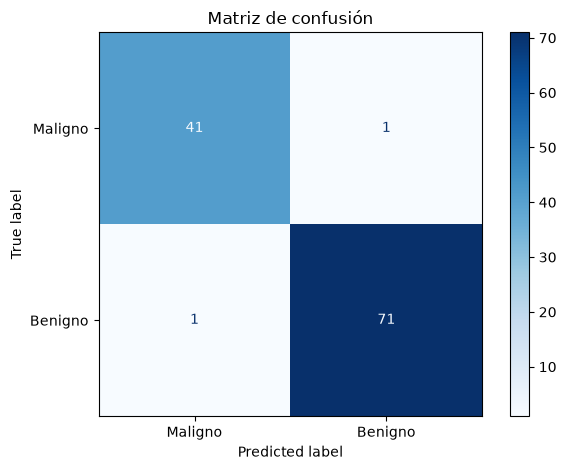

ROC-AUC para malignidad: 0.9954

Predicción para una muestra:
Clase predicha: malignant
Probabilidad estimada de malignidad: 100.00%
Probabilidad estimada de benignidad: 0.00%


: 

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score
)

# 1. Cargar el dataset
dataset = load_breast_cancer(as_frame=True)

X = dataset.data
y = dataset.target

print("Dimensiones:", X.shape)
print("\nPrimeros registros:")
print(X.head())

print("\nDistribución de clases:")
print(y.map({0: "Maligno", 1: "Benigno"}).value_counts())

# 2. Dividir los datos
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 3. Crear el pipeline y entrenar
modelo = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

modelo.fit(X_train, y_train)

# 4. Realizar predicciones
y_pred = modelo.predict(X_test)

# 5. Evaluar el modelo
print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nReporte de clasificación:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Maligno", "Benigno"],
        zero_division=0
    )
)

# 6. Mostrar matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Maligno", "Benigno"],
    cmap="Blues"
)

plt.title("Matriz de confusión")
plt.tight_layout()
plt.show()

# 7. Calcular ROC-AUC para la clase maligna
# La probabilidad de malignidad corresponde a la clase 0.
prob_maligno = modelo.predict_proba(X_test)[:, 0]

auc = roc_auc_score(
    (y_test == 0).astype(int),
    prob_maligno
)

print(f"ROC-AUC para malignidad: {auc:.4f}")

# 8. Clasificar una muestra del conjunto de prueba
muestra = X_test.iloc[[0]]
prediccion = modelo.predict(muestra)[0]
probabilidades = modelo.predict_proba(muestra)[0]

print("\nPredicción para una muestra:")
print("Clase predicha:", dataset.target_names[prediccion])
print(f"Probabilidad estimada de malignidad: {probabilidades[0]:.2%}")
print(f"Probabilidad estimada de benignidad: {probabilidades[1]:.2%}")
